In [ ]:
# 1. Upload your VisionSoC-master.zip file from your computer
from google.colab import files
uploaded = files.upload()  # Choose VisionSoC-master.zip


Saving VisionSoC-master.zip to VisionSoC-master.zip


In [ ]:
# 2. Extract the project and install dependencies
import os, zipfile, glob, sys, subprocess

zip_name = next((name for name in uploaded if name.lower().endswith(".zip")), None)
if zip_name is None:
    raise FileNotFoundError("Please upload VisionSoC-master.zip")

extract_dir = "/content/visionsoc_files"
os.makedirs(extract_dir, exist_ok=True)
with zipfile.ZipFile(zip_name, "r") as zf:
    zf.extractall(extract_dir)

candidates = glob.glob(os.path.join(extract_dir, "**", "RRDBNet_arch.py"), recursive=True)
if not candidates:
    raise FileNotFoundError("RRDBNet_arch.py was not found in the ZIP.")
project_dir = os.path.dirname(candidates[0])
sys.path.insert(0, project_dir)
print("Project directory:", project_dir)

%pip -q install opencv-python-headless scikit-learn matplotlib


Project directory: /content/visionsoc_files/VisionSoC-master


In [ ]:
# 3. Download the actual pretrained ESRGAN checkpoint
import os, requests

model_path = "/content/RRDB_ESRGAN_x4.pth"
weights_url = "https://huggingface.co/databuzzword/esrgan/resolve/main/RRDB_ESRGAN_x4.pth"

if not os.path.exists(model_path) or os.path.getsize(model_path) < 1_000_000:
    with requests.get(weights_url, stream=True, timeout=120) as response:
        response.raise_for_status()
        with open(model_path, "wb") as f:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)

size_mb = os.path.getsize(model_path) / (1024 * 1024)
print(f"Checkpoint downloaded: {size_mb:.1f} MB")
if size_mb < 10:
    raise RuntimeError("The checkpoint appears too small. Check the download URL/network.")


Checkpoint downloaded: 63.8 MB


In [ ]:
# 4. Load the VisionSoC ESRGAN model
import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt
from RRDBNet_arch import RRDBNet

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = RRDBNet(3, 3, 64, 23, gc=32)
state = torch.load(model_path, map_location="cpu")
model.load_state_dict(state, strict=True)
model = model.to(device).eval()
print("Device:", device)
print("ESRGAN model loaded successfully.")


Device: cpu
ESRGAN model loaded successfully.


In [ ]:
# 5. Load images from scikit-learn (no separate dataset download needed)
from sklearn.datasets import load_sample_images

sample_data = load_sample_images()
images = sample_data.images
names = sample_data.filenames
print("Number of sample images:", len(images))
for name, img in zip(names, images):
    print(os.path.basename(name), img.shape, img.dtype)


Number of sample images: 2
china.jpg (427, 640, 3) uint8
flower.jpg (427, 640, 3) uint8


In [ ]:
# 6. Create a low-resolution image and enhance it with ESRGAN
def enhance_rgb_image(lr_rgb):
    # sklearn sample images are RGB; model expects RGB channel order
    x = lr_rgb.astype(np.float32) / 255.0
    x = torch.from_numpy(np.transpose(x, (2, 0, 1))).unsqueeze(0).to(device)
    with torch.no_grad():
        y = model(x).squeeze(0).cpu().clamp(0, 1).numpy()
    y = np.transpose(y, (1, 2, 0))
    return np.clip(y * 255.0, 0, 255).round().astype(np.uint8)

results = []
for name, source in zip(names, images):
    # Crop dimensions to multiples of four so the x4 output matches the crop size.
    h, w = source.shape[:2]
    h4, w4 = (h // 4) * 4, (w // 4) * 4
    original = source[:h4, :w4, :3].astype(np.uint8)

    # Simulate a low-resolution input at 1/4 size.
    lr = cv2.resize(original, (w4 // 4, h4 // 4), interpolation=cv2.INTER_CUBIC)
    bicubic = cv2.resize(lr, (w4, h4), interpolation=cv2.INTER_CUBIC)
    enhanced = enhance_rgb_image(lr)
    results.append((os.path.basename(name), original, lr, bicubic, enhanced))

print("Enhanced", len(results), "images.")


Enhanced 2 images.


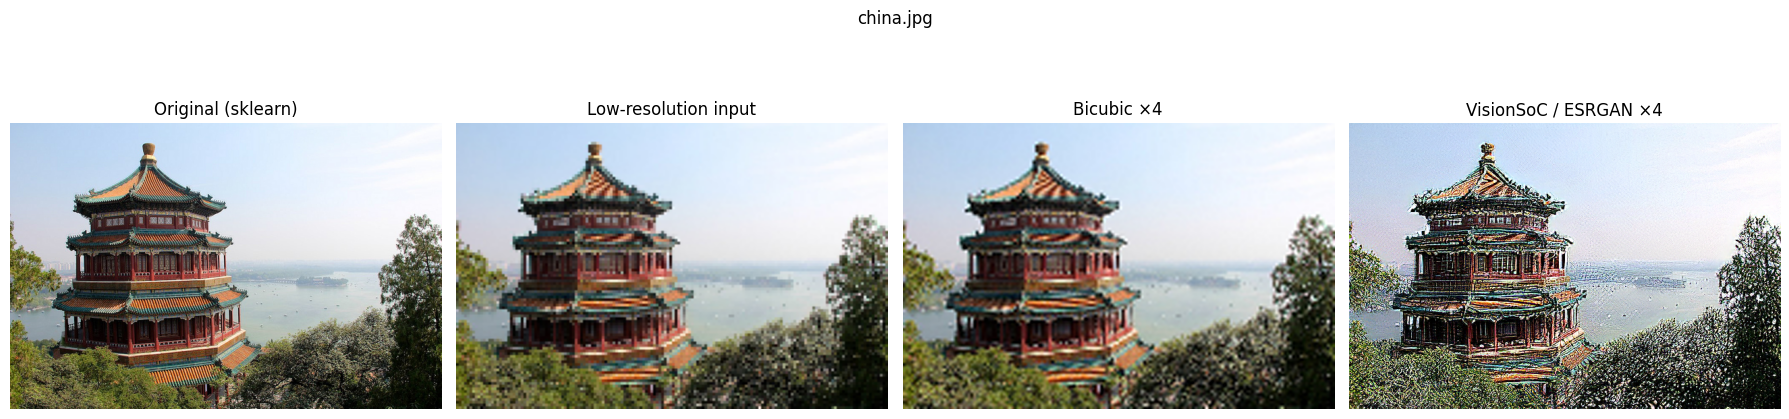

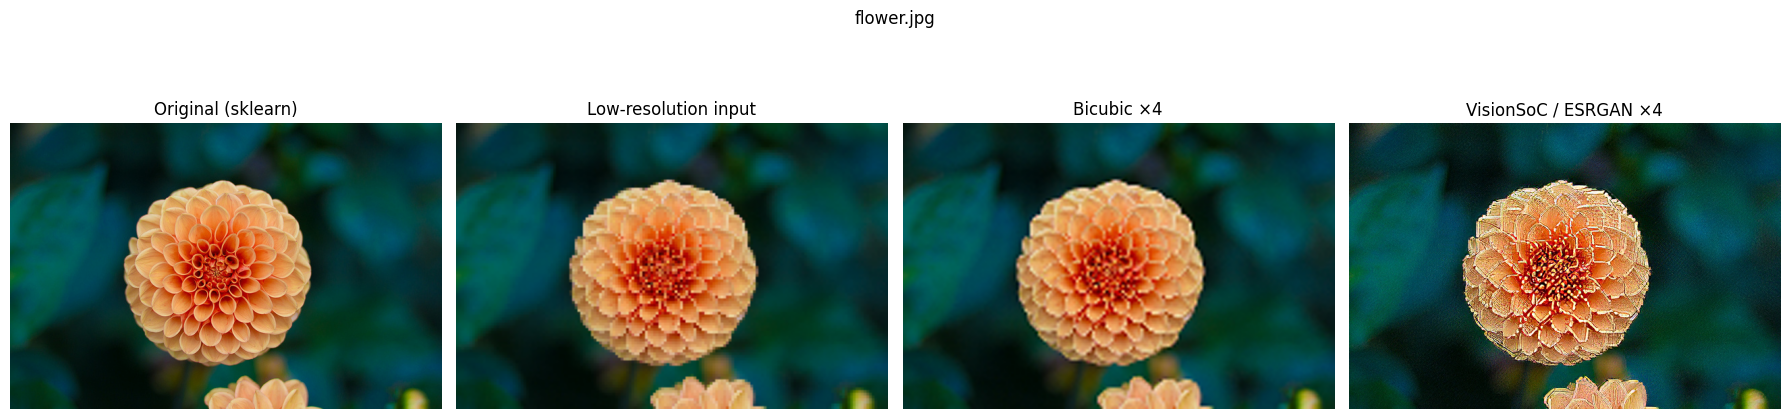

In [ ]:
# 7. Visual comparison: original, low-resolution, bicubic, ESRGAN
for name, original, lr, bicubic, enhanced in results:
    fig, axes = plt.subplots(1, 4, figsize=(18, 5))
    panels = [
        (original, "Original (sklearn)"),
        (lr, "Low-resolution input"),
        (bicubic, "Bicubic ×4"),
        (enhanced, "VisionSoC / ESRGAN ×4"),
    ]
    for ax, (img, title) in zip(axes, panels):
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()


In [ ]:
# 8. Save the enhanced images and download one result
output_dir = "/content/visionsoc_output"
os.makedirs(output_dir, exist_ok=True)

for i, (name, original, lr, bicubic, enhanced) in enumerate(results, start=1):
    out_path = os.path.join(output_dir, f"enhanced_{i}.png")
    cv2.imwrite(out_path, cv2.cvtColor(enhanced, cv2.COLOR_RGB2BGR))
    print(out_path)

from google.colab import files
files.download(os.path.join(output_dir, "enhanced_1.png"))


/content/visionsoc_output/enhanced_1.png
/content/visionsoc_output/enhanced_2.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>